# 📉 Multi-Decade Financial Crashes: S&P 500 Market Shocks (1985–Present)
## Long-Horizon Macro Equity Drawdowns, Flash Crashes & Liquidity Panics

### 1. Incident Background & Multi-Spike Characteristics
Unlike single-event case studies, modern financial markets have experienced recurring catastrophic crash episodes and volatility spikes across decades. When systemic shocks hit, equities exhibit **asymmetric downside velocity**: markets fall dramatically faster than they rise.

Key historical crash episodes in this 40-year benchmark include:
* **1987 "Black Monday" (Oct 19, 1987):** The largest single-day market crash in modern history (**-20.5% in a single session**).
* **1997 Asian Financial Crisis & 1998 Russian Default / LTCM:** Contagion shocks triggering emergency Fed rate cuts.
* **2000–2002 Dot-Com Bubble Collapse:** Extended multi-year crash with multiple steep cascade drawdowns totaling **-49.1%**.
* **2008 Global Financial Crisis (Lehman Collapse):** Cascading banking failures and systemic margin liquidation, producing consecutive daily drops of **-7% to -9%** and a **-56.8%** peak-to-trough collapse.
* **2010 Flash Crash (May 6, 2010):** High-frequency algorithmic liquidity vacuum driving an intraday **-9% plunge** in 36 minutes.
* **2011 US Sovereign Debt Downgrade:** S&P downgrades US credit rating, causing a **-6.7%** single-day plunge.
* **2020 COVID-19 Flash Crash (Feb–March 2020):** Fastest 30% drop in Wall Street history, triggering 4 NYSE circuit-breaker halts in 10 days, including a **-12.0%** crash on March 16.
* **2022 Inflation & Rate-Shock Bear Market:** Aggressive global monetary tightening driving an 11-month **-25.4%** drawdown.
* **August 5, 2024 Global Carry Trade Unwind:** Japanese Yen rate hike triggering a sudden global cross-asset liquidation shock.

### 2. Target Variables ($y$)
* **`SP500_close`**: S&P 500 daily closing price level.
* **`return_pct`**: Daily percentage return ($r_t = \frac{P_t - P_{t-1}}{P_{t-1}} \times 100$).
* **`drawdown_pct`**: Realized peak-to-date drawdown ($DD_t = \frac{P_t - \max_{s \le t} P_s}{\max_{s \le t} P_s} \times 100$).

### 3. Data Source
* Direct Yahoo Finance REST API (`^GSPC`, 1985–Present).
* Fully reproducible with offline fallback caching to `./data/`.


### 📚 Academic Citations & Benchmark Lineage
* **Extreme Value Time Series Prediction:** Ding, D., Zhang, M., Pan, X., Yang, M., & He, X. (2019). *"Modeling Extreme Events in Time Series Prediction."* In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD '19)*, pp. 1114–1122.
* **Market Microstructure Crashes:** Kirilenko, A., Kyle, A. S., Samadi, M., & Tuzun, T. (2017). *"The Flash Crash: High-Frequency Trading in an Electronic Market."* *The Journal of Finance*, 72(3), 967–998.
* **BibTeX Citation:**
```bibtex
@inproceedings{ding2019modeling,
  title={Modeling Extreme Events in Time Series Prediction},
  author={Ding, Daizong and Zhang, Mi and Pan, Xudong and Yang, Min and He, Xiangnan},
  booktitle={Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery \& Data Mining (KDD '19)},
  pages={1114--1122},
  year={2019}
}
@article{kirilenko2017flash,
  title={The Flash Crash: High-Frequency Trading in an Electronic Market},
  author={Kirilenko, Andrei and Kyle, Albert S and Samadi, Mehrdad and Tuzun, Tugkan},
  journal={The Journal of Finance},
  volume={72},
  number={3},
  pages={967--998},
  year={2017}
}
```

In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Libraries loaded and environment initialized successfully!")

Libraries loaded and environment initialized successfully!


### 4. Data Ingestion & Local Caching

In [2]:
def fetch_sp500_multi_decade(start_year=1985, cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'sp500_daily_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading cached S&P 500 daily telemetry from: {cache_path}")
        df = pd.read_csv(cache_path)
        df['date'] = pd.to_datetime(df['date'])
        return df
    
    print(f"Fetching S&P 500 daily price history from {start_year} to present...")
    t1 = int(datetime.datetime(start_year, 1, 1).timestamp())
    t2 = int(datetime.datetime.now().timestamp())
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/%5EGSPC?period1={t1}&period2={t2}&interval=1d'
    headers = {'User-Agent': 'Mozilla/5.0'}
    
    response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()
    res = response.json()['chart']['result'][0]
    
    dates = pd.to_datetime(res['timestamp'], unit='s').tz_localize(None).floor('D')
    quote = res['indicators']['quote'][0]
    
    df = pd.DataFrame({
        'date': dates,
        'SP500_open': quote['open'],
        'SP500_high': quote['high'],
        'SP500_low': quote['low'],
        'SP500_close': quote['close'],
        'SP500_vol': quote['volume']
    }).dropna(subset=['SP500_close']).drop_duplicates(subset=['date']).sort_values('date').reset_index(drop=True)
    
    df.to_csv(cache_path, index=False)
    print(f"Downloaded and cached {len(df)} trading days of S&P 500 data.")
    return df

df_sp = fetch_sp500_multi_decade()
df_sp.head()

Loading cached S&P 500 daily telemetry from: data/sp500_daily_raw.csv


,date,SP500_open,SP500_high,SP500_low,SP500_close,SP500_vol
0,1985-01-02,167.199997,167.199997,165.190002,165.369995,67820000
1,1985-01-03,165.369995,166.110001,164.380005,164.570007,88880000
2,1985-01-04,164.550003,164.550003,163.360001,163.679993,77480000
3,1985-01-07,163.679993,164.710007,163.679993,164.240005,86190000
4,1985-01-08,164.240005,164.589996,163.910004,163.990005,92110000


### 5. Multi-Decade Crash Feature Engineering & Shock Quantification

In [3]:
df_proc = df_sp.copy().sort_values('date').reset_index(drop=True)

# 1. Daily arithmetic return and log return
df_proc['return_pct'] = df_proc['SP500_close'].pct_change() * 100.0
df_proc['log_return'] = np.log(df_proc['SP500_close'] / df_proc['SP500_close'].shift(1))

# 2. Cumulative Rolling Peak (High-Water Mark) and Drawdown Profile
df_proc['peak_to_date'] = df_proc['SP500_close'].cummax()
df_proc['drawdown_pct'] = ((df_proc['SP500_close'] - df_proc['peak_to_date']) / df_proc['peak_to_date']) * 100.0

# 3. Rolling 20-day Annualized Realized Volatility
df_proc['volatility_20d_ann'] = df_proc['return_pct'].rolling(20).std() * np.sqrt(252)

# 4. Rolling Z-Score of Daily Returns (60-day window)
roll_mean = df_proc['return_pct'].rolling(60).mean()
roll_std = df_proc['return_pct'].rolling(60).std()
df_proc['return_zscore_60d'] = (df_proc['return_pct'] - roll_mean) / roll_std

# 5. Automated Multi-Crash Identification
# Flag days with extreme single-day plunge (<= -4.0%)
df_proc['is_crash_day'] = (df_proc['return_pct'] <= -4.0).astype(int)

# Flag severe bear market regime (Drawdown <= -20%)
df_proc['is_bear_regime'] = (df_proc['drawdown_pct'] <= -20.0).astype(int)

print(f"Total Trading Days Analyzed: {len(df_proc):,}")
print(f"Single-Day Flash Crash Days (Return <= -4%): {df_proc['is_crash_day'].sum()}")
print(f"Bear Market Days (Drawdown <= -20%):        {df_proc['is_bear_regime'].sum()}")
print(f"Maximum Historical Drawdown:                {df_proc['drawdown_pct'].min():.2f}%")
print(f"Worst Single-Day Return:                    {df_proc['return_pct'].min():.2f}% on {df_proc.loc[df_proc['return_pct'].idxmin(), 'date'].strftime('%Y-%m-%d')}")
df_proc.head()

Total Trading Days Analyzed: 10,536
Single-Day Flash Crash Days (Return <= -4%): 53
Bear Market Days (Drawdown <= -20%):        2039
Maximum Historical Drawdown:                -56.78%
Worst Single-Day Return:                    -20.47% on 1987-10-19


,date,SP500_open,SP500_high,SP500_low,SP500_close,SP500_vol,return_pct,log_return,peak_to_date,drawdown_pct,volatility_20d_ann,return_zscore_60d,is_crash_day,is_bear_regime
0,1985-01-02,167.199997,167.199997,165.190002,165.369995,67820000,NaN,NaN,165.369995,0.000000,NaN,NaN,0,0
1,1985-01-03,165.369995,166.110001,164.380005,164.570007,88880000,-0.483756,-0.004849,165.369995,-0.483756,NaN,NaN,0,0
2,1985-01-04,164.550003,164.550003,163.360001,163.679993,77480000,-0.540812,-0.005423,165.369995,-1.021952,NaN,NaN,0,0
3,1985-01-07,163.679993,164.710007,163.679993,164.240005,86190000,0.342139,0.003416,165.369995,-0.683310,NaN,NaN,0,0
4,1985-01-08,164.240005,164.589996,163.910004,163.990005,92110000,-0.152216,-0.001523,165.369995,-0.834486,NaN,NaN,0,0


### 6. Timeline Visualizations of 40 Years of Crashes

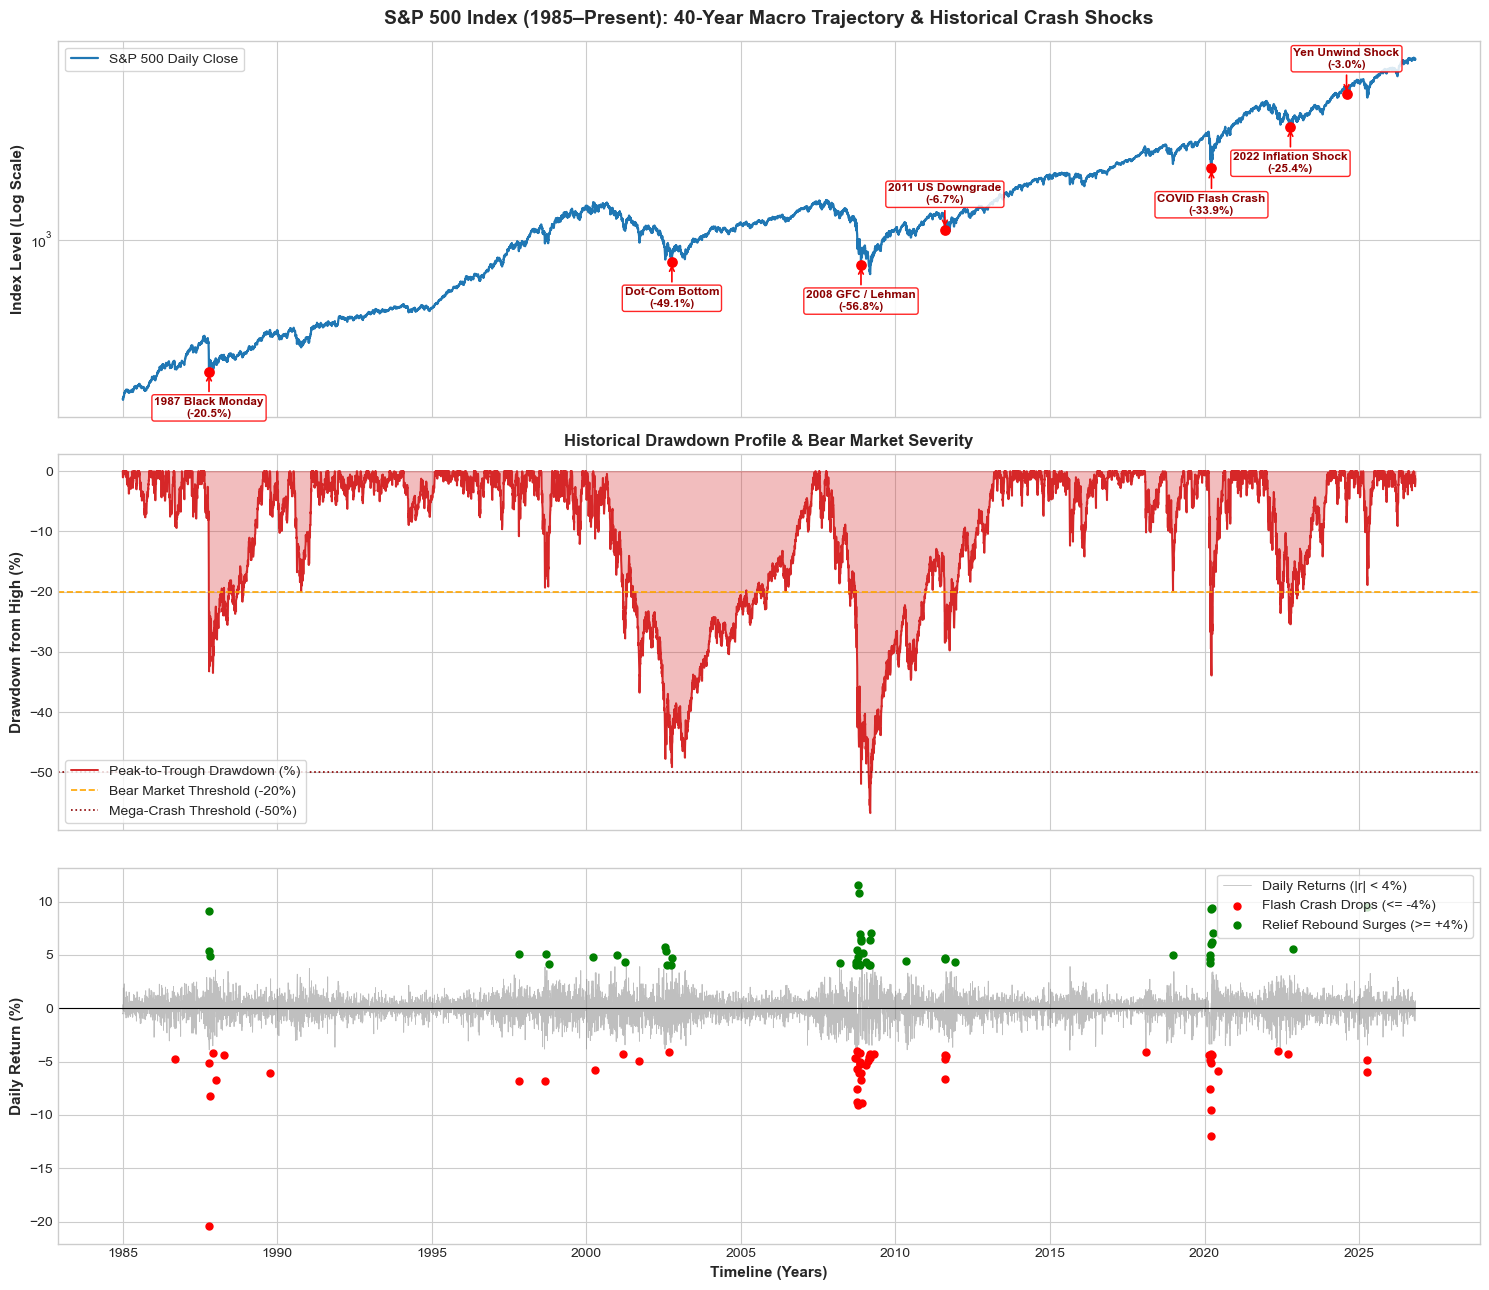

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# 1. Macro Price Trajectory (Log Scale) with Historic Shock Annotations
ax1 = axes[0]
ax1.plot(df_proc['date'], df_proc['SP500_close'], color='#1f77b4', lw=1.6, label='S&P 500 Daily Close')
ax1.set_yscale('log')
ax1.set_title("S&P 500 Index (1985–Present): 40-Year Macro Trajectory & Historical Crash Shocks", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Index Level (Log Scale)", fontsize=11, fontweight='bold')

# Historical Crash Milestones
crash_annotations = [
    ('1987-10-19', '1987 Black Monday\n(-20.5%)', 224, 'bottom'),
    ('2002-10-09', 'Dot-Com Bottom\n(-49.1%)', 776, 'bottom'),
    ('2008-11-20', '2008 GFC / Lehman\n(-56.8%)', 752, 'bottom'),
    ('2011-08-08', '2011 US Downgrade\n(-6.7%)', 1119, 'top'),
    ('2020-03-23', 'COVID Flash Crash\n(-33.9%)', 2237, 'bottom'),
    ('2022-10-12', '2022 Inflation Shock\n(-25.4%)', 3577, 'bottom'),
    ('2024-08-05', 'Yen Unwind Shock\n(-3.0%)', 5186, 'top')
]

for date_str, label, y_pos, va in crash_annotations:
    dt = pd.to_datetime(date_str)
    if dt in df_proc['date'].values:
        actual_val = df_proc.loc[df_proc['date'] == dt, 'SP500_close'].values[0]
        ax1.scatter(dt, actual_val, color='red', s=45, zorder=5)
        ax1.annotate(label, xy=(dt, actual_val), xytext=(dt, actual_val * (0.6 if va=='bottom' else 1.35)),
                     arrowprops=dict(arrowstyle="->", color='red', lw=1.2),
                     fontsize=8.5, fontweight='bold', color='#8b0000', ha='center',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85, edgecolor='red'))

ax1.legend(loc='upper left', frameon=True)

# 2. Historical Drawdown Profile (The "Underwater" Chart)
ax2 = axes[1]
ax2.plot(df_proc['date'], df_proc['drawdown_pct'], color='#d62728', lw=1.4, label='Peak-to-Trough Drawdown (%)')
ax2.fill_between(df_proc['date'], 0, df_proc['drawdown_pct'], color='#d62728', alpha=0.3)
ax2.axhline(-20.0, color='orange', ls='--', lw=1.2, label='Bear Market Threshold (-20%)')
ax2.axhline(-50.0, color='darkred', ls=':', lw=1.2, label='Mega-Crash Threshold (-50%)')
ax2.set_ylabel("Drawdown from High (%)", fontsize=11, fontweight='bold')
ax2.set_title("Historical Drawdown Profile & Bear Market Severity", fontsize=12, fontweight='bold')
ax2.legend(loc='lower left', frameon=True)

# 3. Daily Percentage Return Needles (Impulse Shocks)
ax3 = axes[2]
crash_mask = df_proc['return_pct'] <= -4.0
surge_mask = df_proc['return_pct'] >= 4.0
normal_mask = ~crash_mask & ~surge_mask

ax3.plot(df_proc.loc[normal_mask, 'date'], df_proc.loc[normal_mask, 'return_pct'], 
         color='gray', alpha=0.5, lw=0.6, label='Daily Returns (|r| < 4%)')
ax3.scatter(df_proc.loc[crash_mask, 'date'], df_proc.loc[crash_mask, 'return_pct'], 
            color='red', s=25, label='Flash Crash Drops (<= -4%)', zorder=4)
ax3.scatter(df_proc.loc[surge_mask, 'date'], df_proc.loc[surge_mask, 'return_pct'], 
            color='green', s=25, label='Relief Rebound Surges (>= +4%)', zorder=4)
ax3.axhline(0, color='black', lw=0.8)
ax3.set_ylabel("Daily Return (%)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Timeline (Years)", fontsize=11, fontweight='bold')
ax3.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('data/sp500_crashes_timeline.png', dpi=300)
plt.show()

### 7. Statistical Crash Anatomy: Top 10 Single-Day Market Plunges

In [5]:
# Top 10 worst single-day drops
top_drops = df_proc.sort_values('return_pct').head(10)[['date', 'SP500_close', 'return_pct', 'drawdown_pct', 'volatility_20d_ann']]
top_drops['date'] = top_drops['date'].dt.strftime('%Y-%m-%d')
print("=== Top 10 Steepest Single-Day S&P 500 Market Crashes (1985–Present) ===")
print(top_drops.to_string(index=False))

# Export clean processed dataset
out_path = 'data/sp500_crashes_processed.csv'
df_proc.to_csv(out_path, index=False)
print(f"\nProcessed multi-crash dataset successfully saved to: {out_path}")

=== Top 10 Steepest Single-Day S&P 500 Market Crashes (1985–Present) ===
      date  SP500_close  return_pct  drawdown_pct  volatility_20d_ann
1987-10-19   224.839996  -20.466931    -33.236332           76.593922
2020-03-16  2386.129883  -11.984055    -29.532657           79.660294
2020-03-12  2480.639893   -9.511268    -26.741581           58.382997
2008-10-15   907.840027   -9.034978    -41.996613           79.978651
2008-12-01   816.210022   -8.929524    -47.851004           75.626043
2008-09-29  1106.420044   -8.806776    -29.309010           51.410852
1987-10-26   227.669998   -8.278947    -32.395996           90.841641
2008-10-09   909.919983   -7.616710    -41.863721           62.128803
2020-03-09  2746.560059   -7.596970    -18.888409           43.929699
1997-10-27   876.989990   -6.865684    -10.795224           28.267933

Processed multi-crash dataset successfully saved to: data/sp500_crashes_processed.csv
